# Поведенческий скоринг: прогноз просрочки от 90 дней на горизонте 12 месяцев

**Суть проекта**

Банк «Ва-банк» сталкивается с ростом просрочек в сегменте потребительского кредитования. Классические заявочные скоринговые модели оценивают клиента только в момент выдачи кредита и не отслеживают, что происходит с ним дальше. В результате банк не видит заранее ухудшения платёжного поведения уже действующих заёмщиков и вынужден замораживать избыточные резервы под возможные потери.

Задача проекта — построить модель поведенческого скоринга, которая по накопленной истории клиента на дату скоринга оценивает вероятность того, что в течение следующих 12 месяцев у него возникнет просрочка длительностью от 90 дней.

Ключевое ограничение — временная структура данных: в признаки допускается только информация, доступная строго до score_date, иначе возникнет утечка данных из будущего.

Результат нужен бизнесу не как максимум одной метрики, а как компромисс трёх показателей: approval rate не менее 65%, default rate не более 2%, missed defaults rate не более 4%.

## Перевод бизнес-задачи на язык машинного обучения

**Тип задачи**

Бинарная классификация с временной структурой. Объект — пара «клиент + score_date», целевая переменная target ∈ {0, 1}: возникнет ли у клиента эпизод просрочки от 90 дней в интервале [score_date, score_date + 365 дней).

Модель должна возвращать не метку класса, а откалиброванную вероятность дефолта: бизнес-решение принимается через порог, который подбирается отдельно под ограничения по approval rate, default rate и missed defaults rate.

**Модели:**   
- Базовый уровень: логистическая регрессия и случайный лес, каждый в двух вариантах — без балансировки и с балансировкой. Итого четыре базовые модели для сравнения.
- Итоговое решение: RandomForestClassifier с выбранной стратегией балансировки. Гиперпараметры, подобранные через Optuna, целевая функция оптимизации — missed defaults rate, усреднённая по фолдам.
- Калибровка: лучшая модель обучается на полной обучающей выборке, затем калибруется на отдельной калибровочной выборке, качество вероятностей оценивается коэффициентом Бриера до и после калибровки. 

## Загрузка необходимых библиотек

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import optuna
import warnings

from sklearn.metrics import (confusion_matrix, 
                             roc_auc_score, 
                             brier_score_loss, 
                             accuracy_score, 
                             precision_score, 
                             recall_score,
                             f1_score)
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.calibration import calibration_curve

from mlxtend.evaluate import GroupTimeSeriesSplit

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

In [3]:
RS = 42

## Загрузка данных

In [4]:
loan = pd.read_csv('data/ds_15_loan_payment_credit.csv', parse_dates = ['дата_начала_периода'])
loan.head(5)

,ID,дата_начала_периода,просрочка_дней
0,IDF55109846,2014-12-01,120
1,IDF54995533,2015-06-01,121
2,IDF54964538,2018-03-01,87
3,IDF55079777,2019-09-01,109
4,IDF55093915,2017-02-01,84


In [5]:
trans = pd.read_csv('data/ds_15_transactions.csv', parse_dates = ['date'])
trans.head(5)

,ID,date,MCC_5300,MCC_5814,MCC_5812,MCC_5411,MCC_3990,MCC_5722,MCC_4900,MCC_другое
0,IDF55109846,2013-05-01,3267.59,1282.11,1457.96,5711.10,647.43,2374.78,4059.86,3657.35
1,IDF55109846,2013-06-01,3196.58,2443.37,1334.20,5824.65,1067.55,2187.11,4592.26,3322.61
2,IDF55109846,2013-07-01,3550.54,4277.72,1463.75,5209.51,1167.95,2076.54,3605.25,3467.06
3,IDF55109846,2013-08-01,3385.98,4530.63,1261.40,5765.96,986.99,2231.77,2209.39,3354.44
4,IDF55109846,2013-09-01,3214.84,4146.65,1405.15,5632.11,640.76,2156.67,1519.46,4352.90


In [6]:
client = pd.read_csv('data/ds_15_client_description.csv', parse_dates = ['дата_регистрации'])
client.head(5)

,ID,возраст,семейное_положение,наличие_иждивенцев,дата_регистрации
0,IDF55109846,41,разведённые,1,2013-05-01
1,IDF54900291,45,разведённые,1,2017-12-01
2,IDF54995533,34,разведённые,1,2013-11-01
3,IDF55065581,40,нет семьи,1,2018-08-01
4,IDF55057353,66,разведённые,0,2018-05-01


In [7]:
credit = pd.read_csv('data/ds_15_credit_description.csv')
credit.head(5)

,ID,доход,сумма_кредита
0,IDF55109846,27035,1960785
1,IDF54900291,64502,3375810
2,IDF54995533,90477,401700
3,IDF55065581,133475,1952655
4,IDF55057353,51324,1107870


In [8]:
mortgage = pd.read_csv('data/ds_15_mortgage_presence.csv', parse_dates = ['дата_открытия'])
mortgage.head(5)

,ID,дата_открытия,наличие_ипотеки
0,IDF54896351,2013-03-01,1
1,IDF54896367,2018-01-01,1
2,IDF54896414,2018-02-01,1
3,IDF54896494,2019-02-01,1
4,IDF54896615,2018-12-01,1


In [9]:
rating = pd.read_csv('data/ds_15_credit_rating.csv', parse_dates = ['date'])
rating.head(5)

,ID,date,кредитный_рейтинг
0,IDF55109846,2013-05-01,692
1,IDF55109846,2013-06-01,688
2,IDF55109846,2013-07-01,666
3,IDF55109846,2013-08-01,692
4,IDF55109846,2013-09-01,688


In [10]:
macro = pd.read_csv('data/ds_15_macro_data.csv', parse_dates = ['date'])
macro.head(5)

,date,учетная_ставка,уровень_безработицы,инфляция
0,2013-01-01,5.5,5.7,0.97
1,2013-02-01,5.5,5.8,0.56
2,2013-03-01,5.5,5.9,0.34
3,2013-04-01,5.5,5.5,0.51
4,2013-05-01,5.5,5.4,0.66


In [11]:
cohort = pd.read_csv('data/ds_15_cohort_grid.csv', parse_dates = ['score_date'])
cohort.head(5)

,ID,score_date
0,IDF55109846,2013-05-01
1,IDF55109846,2013-06-01
2,IDF55109846,2013-07-01
3,IDF55109846,2013-08-01
4,IDF55109846,2013-09-01


In [12]:
tables = [loan, trans, client, credit, mortgage, rating, macro, cohort]

 Для удобства составим список с названиями таблиц

## Исследовательский анализ данных

In [13]:
for table in tables:
    print(table.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   ID                   5500 non-null   object        
 1   дата_начала_периода  5500 non-null   datetime64[ns]
 2   просрочка_дней       5500 non-null   int64         
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 129.0+ KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 577494 entries, 0 to 577493
Data columns (total 10 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   ID          577494 non-null  object        
 1   date        577494 non-null  datetime64[ns]
 2   MCC_5300    577494 non-null  float64       
 3   MCC_5814    577494 non-null  float64       
 4   MCC_5812    577494 non-null  float64       
 5   MCC_5411    577494 non-null  float64       
 6   MCC_3990    577494 non-nu

In [14]:
for table in tables:
    print(table.describe())

       просрочка_дней
count     5500.000000
mean       114.748000
std         20.362422
min         80.000000
25%         97.000000
50%        115.000000
75%        132.000000
max        150.000000
            MCC_5300       MCC_5814       MCC_5812       MCC_5411  \
count  577494.000000  577494.000000  577494.000000  577494.000000   
mean     6177.123479    3507.682295    2993.862550    9263.099506   
std      8835.871514    5710.755226    4541.119582   12299.732992   
min       162.910000      62.180000      67.060000     286.110000   
25%      1360.880000     583.480000     611.540000    2139.480000   
50%      2659.590000    1233.110000    1224.530000    4115.385000   
75%      6561.467500    3642.392500    3201.612500    9287.545000   
max     86939.400000   55720.690000   47969.570000  101301.950000   

            MCC_3990       MCC_5722       MCC_4900     MCC_другое  
count  577494.000000  577494.000000  577494.000000  577494.000000  
mean     1128.116742    3604.437043    3682.

In [15]:
tables_id = [loan, trans, client, credit, mortgage, rating, cohort]

In [16]:
for table in tables_id:
    print(table.groupby('ID')['ID'].count().max())

1
84
1
1
1
84
84


In [17]:
for table in tables_id:
    print(table.duplicated().sum())

0
0
0
0
0
0
0


 Все таблицы не имеют пропусков и дубликатов, при загрузке данных специально было установлен параметр для загрузки дат в формате datetime, остальные столбцы также имеют корректный тип данных. Таблицы с информациях о задолжности, данных клиента, кредите и ипотеке имеют уникальные данные по каждому айди, остальные таблицы имеют структуру многие ко многим, максимальное число наблюдений для одного айди составляет 84 строки.

Text(0.5, 0, 'дней')

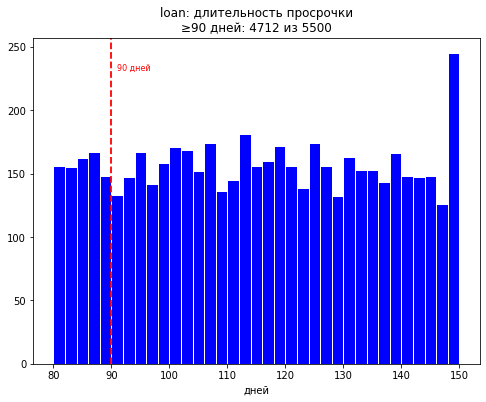

In [18]:
fig = plt.figure(figsize=(8, 6))
 
# 1. просрочка_дней
plt.hist(loan['просрочка_дней'], bins=35, color='blue', edgecolor='white')
plt.axvline(90, color='red', ls='--', lw=1.8)
plt.text(91, plt.ylim()[1] * 0.9, '90 дней', color='red', fontsize=8)
n90 = (loan['просрочка_дней'] >= 90).sum()
plt.title(f'loan: длительность просрочки\n≥90 дней: {n90} из {len(loan)}')
plt.xlabel('дней')

 Длительность просрочки имеет диапазон от 80 до 150 дней, где таргет нашей целевой составляет 90, по графику видно, что основная доля наблюдений более 90, скопление наблюдений в 150 говорит о наличии множества клиентов с длительной просрочкой.

Text(0.5, 0, 'лет')

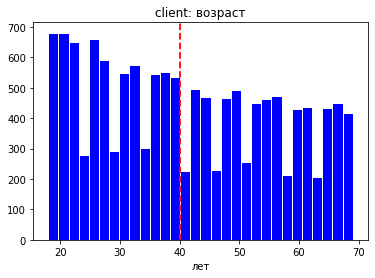

In [19]:
# 2. возраст
plt.hist(client['возраст'], bins=30, color='blue', edgecolor='white')
plt.axvline(client['возраст'].median(), color='red', ls='--', lw=1.8)
plt.title('client: возраст')
plt.xlabel('лет')

 Диапазон 18–69 лет, медиана 40. Границы естественные для кредитного портфеля, выбросов и нереалистичных значений нет. Распределение неравномерное, но без выраженных провалов.

(0.0, 5409.12)

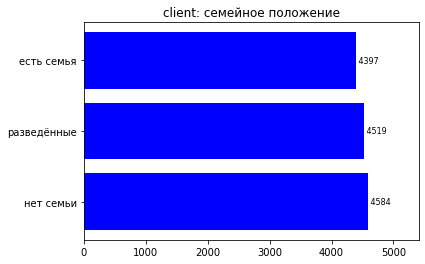

In [20]:
vc = client['семейное_положение'].value_counts()
plt.barh(vc.index, vc.values, color='blue')
for i, v in enumerate(vc.values):
    plt.text(v, i, f' {v}', va='center', fontsize=8)
plt.title('client: семейное положение')
plt.xlim(0, vc.max() * 1.18)

(0.0, 8208.08)

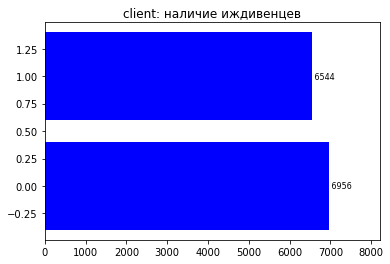

In [21]:
dp = client['наличие_иждивенцев'].value_counts()
plt.barh(dp.index, dp.values, color='blue')
for i, d in enumerate(dp.values):
    plt.text(d, i, f' {d}', va='center', fontsize=8)
plt.title('client: наличие иждивенцев')
plt.xlim(0, dp.max() * 1.18)

 Три категории распределены практически поровну: «нет семьи» — 4584, «разведённые» — 4519, «есть семья» — 4397. Набор значений совпадает с описанием данных, лишних категорий и разночтений в написании нет. Признак категориальный, требует кодирования через OneHotEncoder. Признак наличие_иждивенцев тоже сбалансирован: 6956 против 6544.

Text(0.5, 0, 'тыс. руб./мес.')

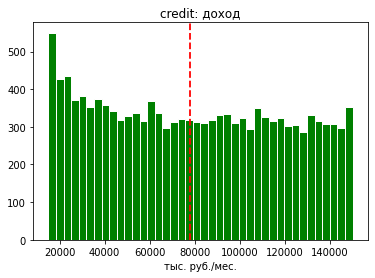

In [22]:
plt.hist(credit['доход'], bins=40, color='green', edgecolor='white')
plt.axvline(credit['доход'].median(), color='red', ls='--', lw=1.8)
plt.title('credit: доход')
plt.xlabel('тыс. руб./мес.')

 От 15 000 до 150 000 руб./мес., медиана 77 991. Распределение равномерное, нулевых и отрицательных значений нет.

Text(0.5, 0, 'млн руб.')

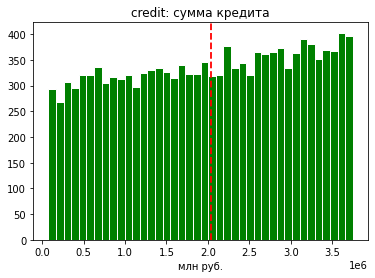

In [23]:
plt.hist(credit['сумма_кредита'], bins=40, color='green', edgecolor='white')
plt.axvline(credit['сумма_кредита'].median(), color='red', ls='--', lw=1.8)
plt.title('credit: сумма кредита')
plt.xlabel('млн руб.')

  От 75 тыс. до 3,75 млн руб., медиана 2,03 млн. Распределение снова равномерное. Аномалий нет.

Text(0.5, 0, 'месячных доходов')

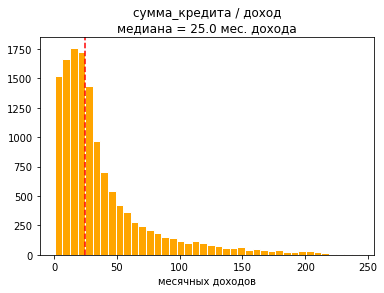

In [24]:
ratio = credit['сумма_кредита'] / credit['доход']
plt.hist(ratio, bins=40, color='orange', edgecolor='white')
plt.axvline(ratio.median(), color='red', ls='--', lw=1.5)
plt.title(f'сумма_кредита / доход\nмедиана = {ratio.median():.1f} мес. дохода')
plt.xlabel('месячных доходов')

 Медиана 25 месячных доходов, максимум 243. Значения для потребительского кредита неправдоподобно высокие, реальный банк такую нагрузку не одобрит.

Text(0.5, 0, 'балл')

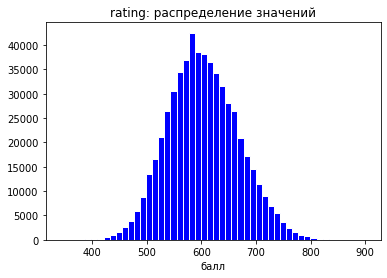

In [25]:
plt.hist(rating['кредитный_рейтинг'], bins=50, color='blue', edgecolor='white')
plt.title('rating: распределение значений')
plt.xlabel('балл')

 Диапазон 343–900, среднее 603, стандартное отклонение 64. Форма близка к нормальной, аномальных пиков нет. Значения правдоподобны для шкалы кредитного рейтинга.

Text(0.5, 1.0, 'loan: число стартов просрочек по месяцам')

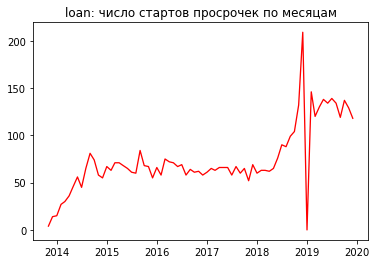

In [26]:
cnt = loan.set_index('дата_начала_периода').resample('MS').size()
plt.plot(cnt.index, cnt.values, color='red', lw=1.3)
plt.title('loan: число стартов просрочек по месяцам')

 Медианно 66 эпизодов в месяц, к концу периода уровень растёт примерно вдвое, максимум — 209 в декабре 2018 года.

 Найдена аномалия: в январе 2019 года стартов просрочек ноль. При 209 в декабре 2018 и 146 в феврале 2019 это провал, необъяснимый сезонностью. Похоже на пропуск в выгрузке за один месяц. На расчёт таргета это влияет ограниченно — клиенты с дефолтом в январе 2019 просто отсутствуют, — но при разбиении выборок по времени этот месяц попадёт в один из фолдов и слегка исказит долю целевого класса. Стоит зафиксировать в выводах, специально ничего не исправляя.

Text(0.5, 0, 'руб./мес.')

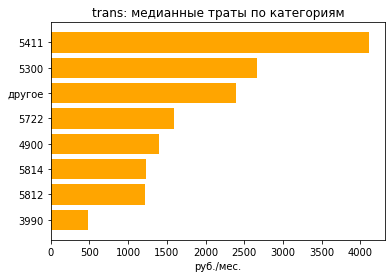

In [27]:
mcc = [c for c in trans.columns if c.startswith('MCC')]
med_mcc = trans[mcc].median().sort_values()
plt.barh([c.replace('MCC_', '') for c in med_mcc.index], med_mcc.values, color='orange')
plt.title('trans: медианные траты по категориям')
plt.xlabel('руб./мес.')

 Структура расходов правдоподобна: продукты (5411) — 4115 руб., маркетплейсы (5300) — 2660, прочее — 2398, техника (5722) — 1590, ЖКУ (4900) — 1397, кафе и фастфуд (5812, 5814) — по 1230, экосистема Яндекса (3990) — 477. Порядок величин соответствует реальному потребительскому профилю.

Text(0.5, 1.0, 'trans: суммарные траты по месяцам, млн руб.')

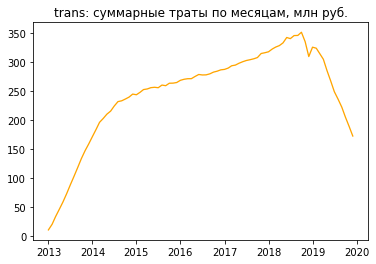

In [28]:
tot = trans.groupby('date')[mcc].sum().sum(axis=1) / 1e6
plt.plot(tot.index, tot.values, color='orange', lw=1.3)
plt.title('trans: суммарные траты по месяцам, млн руб.')

 Суммарные траты растут с 10 млн руб. в январе 2013 до пика около 351 млн, после чего снижаются до 172 млн к декабрю 2019 — при том, что число клиентов в эти месяцы продолжает расти.

Text(0.5, 0, 'месяцев')

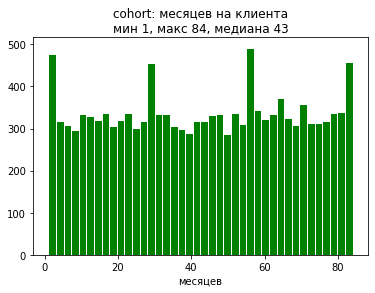

In [29]:
hist_len = cohort.groupby('ID').size()
plt.hist(hist_len, bins=40, color='green', edgecolor='white')
plt.title(f'cohort: месяцев на клиента\nмин {hist_len.min()}, макс {hist_len.max()}, медиана {int(hist_len.median())}')
plt.xlabel('месяцев')

  Длина истории каждого зафиксированного клиента от 1 до 84 месяцев, медиана 43, у всех заканчивается декабрём 2019.

## Объединение таблиц
### Формирование целевой переменной
### Создание итоговой таблицы

In [30]:
defaults = loan[loan['просрочка_дней']>=90].copy()
defaults = defaults.loc[defaults.groupby('ID')['дата_начала_периода'].idxmin()]
defaults.head()

,ID,дата_начала_периода,просрочка_дней
1789,IDF54896351,2014-10-01,93
5295,IDF54896494,2019-07-01,137
2516,IDF54896677,2017-09-01,90
53,IDF54896685,2017-11-01,136
2004,IDF54896744,2019-02-01,97


  Отделим таблицу, где оставим информацию только о просрочках более или равно 90 дней.

In [31]:
cohort_loan = cohort.merge(defaults, on='ID', how='left')
cohort_loan.head()

,ID,score_date,дата_начала_периода,просрочка_дней
0,IDF55109846,2013-05-01,2014-12-01,120.0
1,IDF55109846,2013-06-01,2014-12-01,120.0
2,IDF55109846,2013-07-01,2014-12-01,120.0
3,IDF55109846,2013-08-01,2014-12-01,120.0
4,IDF55109846,2013-09-01,2014-12-01,120.0


 Соединим основную таблицу с датами скоринга и таблицу с просрочками 90+ дней, мержевать будем с помощью left, чтобы в таблице скоринга остались данные по клиентам без просрочек.

In [32]:
cohort_loan['target'] = (
    (cohort_loan['score_date'] <= cohort_loan['дата_начала_периода']) &
    (cohort_loan['дата_начала_периода'] < cohort_loan['score_date'] + pd.DateOffset(months=12))
).astype(int)

 Введем столбец с целевой переменной, используя условия из задания.

In [33]:
cohort_loan = cohort_loan[~(cohort_loan['дата_начала_периода'] < cohort_loan['score_date'])]

 Удалим данные, где уже была просрочка.

In [34]:
cohort_loan = cohort_loan.merge(client, on='ID', how='left')
cohort_loan['months_from_reg']= (
    cohort_loan['score_date'].dt.year - cohort_loan['дата_регистрации'].dt.year) * 12 + \
    (cohort_loan['score_date'].dt.month - cohort_loan['дата_регистрации'].dt.month)
cohort_loan

,ID,score_date,дата_начала_периода,просрочка_дней,target,возраст,семейное_положение,наличие_иждивенцев,дата_регистрации,months_from_reg
0,IDF55109846,2013-05-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,0
1,IDF55109846,2013-06-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,1
2,IDF55109846,2013-07-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,2
3,IDF55109846,2013-08-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,3
4,IDF55109846,2013-09-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,4
...,...,...,...,...,...,...,...,...,...,...
438374,IDF54902735,2015-01-01,2015-04-01,112.0,1,27,разведённые,0,2014-03-01,10
438375,IDF54902735,2015-02-01,2015-04-01,112.0,1,27,разведённые,0,2014-03-01,11
438376,IDF54902735,2015-03-01,2015-04-01,112.0,1,27,разведённые,0,2014-03-01,12
438377,IDF54902735,2015-04-01,2015-04-01,112.0,1,27,разведённые,0,2014-03-01,13


 Добавим данные из таблицы с информацией о каждом клиенте, так как модели в качестве признаков могут использовать только числовые значения, дату регистрации переделаем в числовой признак, обозначающий количество месяцев с момента регистрации.

In [35]:
cohort_loan = cohort_loan.merge(credit, on='ID', how='left')
cohort_loan

,ID,score_date,дата_начала_периода,просрочка_дней,target,возраст,семейное_положение,наличие_иждивенцев,дата_регистрации,months_from_reg,доход,сумма_кредита
0,IDF55109846,2013-05-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,0,27035,1960785
1,IDF55109846,2013-06-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,1,27035,1960785
2,IDF55109846,2013-07-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,2,27035,1960785
3,IDF55109846,2013-08-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,3,27035,1960785
4,IDF55109846,2013-09-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,4,27035,1960785
...,...,...,...,...,...,...,...,...,...,...,...,...
438374,IDF54902735,2015-01-01,2015-04-01,112.0,1,27,разведённые,0,2014-03-01,10,133821,389610
438375,IDF54902735,2015-02-01,2015-04-01,112.0,1,27,разведённые,0,2014-03-01,11,133821,389610
438376,IDF54902735,2015-03-01,2015-04-01,112.0,1,27,разведённые,0,2014-03-01,12,133821,389610
438377,IDF54902735,2015-04-01,2015-04-01,112.0,1,27,разведённые,0,2014-03-01,13,133821,389610


In [36]:
cohort_loan = cohort_loan.merge(mortgage[['ID', 'дата_открытия']], on='ID', how='left')
cohort_loan['ипотека'] = (cohort_loan['дата_открытия'] < cohort_loan['score_date']).astype(int)
cohort_loan

,ID,score_date,дата_начала_периода,просрочка_дней,target,возраст,семейное_положение,наличие_иждивенцев,дата_регистрации,months_from_reg,доход,сумма_кредита,дата_открытия,ипотека
0,IDF55109846,2013-05-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,0,27035,1960785,NaT,0
1,IDF55109846,2013-06-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,1,27035,1960785,NaT,0
2,IDF55109846,2013-07-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,2,27035,1960785,NaT,0
3,IDF55109846,2013-08-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,3,27035,1960785,NaT,0
4,IDF55109846,2013-09-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,4,27035,1960785,NaT,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
438374,IDF54902735,2015-01-01,2015-04-01,112.0,1,27,разведённые,0,2014-03-01,10,133821,389610,NaT,0
438375,IDF54902735,2015-02-01,2015-04-01,112.0,1,27,разведённые,0,2014-03-01,11,133821,389610,NaT,0
438376,IDF54902735,2015-03-01,2015-04-01,112.0,1,27,разведённые,0,2014-03-01,12,133821,389610,NaT,0
438377,IDF54902735,2015-04-01,2015-04-01,112.0,1,27,разведённые,0,2014-03-01,13,133821,389610,NaT,0


 Добавим данные из таблиц с информацией о кредитах и ипотеках (только те, что уже открыты на момент скоринга).

In [37]:
trans = trans.sort_values(['ID', 'date'])
mcc = [c for c in trans.columns if c.startswith('MCC')]
trans['всего'] = trans[mcc].sum(axis=1)

In [38]:
def win(col, lag, w=3):
    """Среднее за w месяцев, начиная с lag месяцев назад."""
    return trans.groupby('ID')[col].transform(
        lambda s: s.shift(lag).rolling(w).mean())

for c in mcc + ['всего']:
    trans[f'{c}_m3'] = win(c, lag=1)      # месяцы t-1, t-2, t-3
trans['всего_m3_prev'] = win('всего', lag=4)   # месяцы t-4, t-5, t-6

In [39]:
trans['траты_дин_3_6'] = trans['всего_m3'] / trans['всего_m3_prev']

trans['доля_обязательных'] = (trans['MCC_5411_m3'] + trans['MCC_4900_m3']) / trans['всего_m3']

disc = ['MCC_5814', 'MCC_5812', 'MCC_3990', 'MCC_5722']
trans['доля_дискреционных'] = trans[[f'{c}_m3' for c in disc]].sum(axis=1) / trans['всего_m3']

In [40]:
feat = ([f'{c}_m3' for c in mcc] + ['всего_m3', 'траты_дин_3_6',
        'доля_обязательных', 'доля_дискреционных'])

trans_feat = trans[['ID', 'date'] + feat].rename(columns={'date': 'score_date'})

cohort_loan = cohort_loan.merge(trans_feat, on=['ID', 'score_date'], how='left')
cohort_loan.head(5)

,ID,score_date,дата_начала_периода,просрочка_дней,target,возраст,семейное_положение,наличие_иждивенцев,дата_регистрации,months_from_reg,...,MCC_5812_m3,MCC_5411_m3,MCC_3990_m3,MCC_5722_m3,MCC_4900_m3,MCC_другое_m3,всего_m3,траты_дин_3_6,доля_обязательных,доля_дискреционных
0,IDF55109846,2013-05-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,IDF55109846,2013-06-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,IDF55109846,2013-07-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,IDF55109846,2013-08-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,3,...,1418.636667,5581.753333,960.976667,2212.81,4085.790000,3482.34,23748.276667,NaN,0.407084,0.305713
4,IDF55109846,2013-09-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,4,...,1353.116667,5600.040000,1074.163333,2165.14,3468.966667,3381.37,24171.070000,NaN,0.375201,0.345164


 Из таблицы с транзакциями сразу выведем новые признаки, которые не заглядывают в будущее.  По каждому MCC сделаем признак со средним значением за предыдущие 3 месяца, среднее значение обзей суммы трат за предыдущие 3 месяца, изменение трат 3 и 6 месяцев назад, доля обязательных MCC и дискреционных. Присоединим к общей таблице, удаление ненужных признаков осуществим в конце.

In [42]:
rating = rating.sort_values(['ID', 'date'])
g = rating.groupby('ID')['кредитный_рейтинг']

rating['рейтинг_lag1'] = g.shift(1)
rating['рейтинг_изм_3м'] = g.transform(lambda s: s.shift(1) - s.shift(4))

In [43]:
cols = ['рейтинг_lag1', 'рейтинг_изм_3м']

rating_feat = (rating[['ID', 'date'] + cols]
               .rename(columns={'date': 'score_date'}))

cohort_loan = cohort_loan.merge(rating_feat, on=['ID', 'score_date'], how='left')

 Из таблицы с рейтингом также сразу выведем новые признаки, которые не заглядывают в будущее. Рейтинг прошлого месяца, разница между рейтингом прошлого месяца и 3 месяца назад.

In [44]:
macro_shifted = macro.copy()
macro_shifted['date'] = macro_shifted['date'] + pd.DateOffset(months=1)

cohort_loan = cohort_loan.merge(macro_shifted, left_on='score_date', right_on='date', how='left')
cohort_loan = cohort_loan.drop(columns='date')

cohort_loan.head(5)

,ID,score_date,дата_начала_периода,просрочка_дней,target,возраст,семейное_положение,наличие_иждивенцев,дата_регистрации,months_from_reg,...,MCC_другое_m3,всего_m3,траты_дин_3_6,доля_обязательных,доля_дискреционных,рейтинг_lag1,рейтинг_изм_3м,учетная_ставка,уровень_безработицы,инфляция
0,IDF55109846,2013-05-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.5,5.5,0.51
1,IDF55109846,2013-06-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,1,...,NaN,NaN,NaN,NaN,NaN,692.0,NaN,5.5,5.4,0.66
2,IDF55109846,2013-07-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,2,...,NaN,NaN,NaN,NaN,NaN,688.0,NaN,5.5,5.3,0.42
3,IDF55109846,2013-08-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,3,...,3482.34,23748.276667,NaN,0.407084,0.305713,666.0,NaN,5.5,5.3,0.82
4,IDF55109846,2013-09-01,2014-12-01,120.0,0,41,разведённые,1,2013-05-01,4,...,3381.37,24171.070000,NaN,0.375201,0.345164,692.0,0.0,5.5,5.2,0.14


 Таблицу с макро-показателям просто сдвинем на один месяц, получатся значения за предыдущий.

In [45]:
cohort_loan = cohort_loan.drop(columns=['дата_начала_периода', 'просрочка_дней', 'дата_регистрации', 'дата_открытия'])

In [46]:
cohort_loan.columns

Index(['ID', 'score_date', 'target', 'возраст', 'семейное_положение',
       'наличие_иждивенцев', 'months_from_reg', 'доход', 'сумма_кредита',
       'ипотека', 'MCC_5300_m3', 'MCC_5814_m3', 'MCC_5812_m3', 'MCC_5411_m3',
       'MCC_3990_m3', 'MCC_5722_m3', 'MCC_4900_m3', 'MCC_другое_m3',
       'всего_m3', 'траты_дин_3_6', 'доля_обязательных', 'доля_дискреционных',
       'рейтинг_lag1', 'рейтинг_изм_3м', 'учетная_ставка',
       'уровень_безработицы', 'инфляция'],
      dtype='object')

In [47]:
rename_dict = {
    'ID': 'id', 
    'score_date': 'score_date', 
    'target': 'target', 
    'возраст': 'age', 
    'семейное_положение': 'marital_status',
    'наличие_иждивенцев': 'dependents', 
    'months_from_reg': 'months_since_reg', 
    'доход': 'income', 
    'сумма_кредита': 'loan_amount',
    'ипотека': 'mortgage', 
    'MCC_5300_m3': 'mcc_5300_spend_3m', 
    'MCC_5814_m3': 'mcc_5814_spend_3m', 
    'MCC_5812_m3': 'mcc_5812_spend_3m', 
    'MCC_5411_m3': 'mcc_5411_spend_3m',
    'MCC_3990_m3': 'mcc_3990_spend_3m', 
    'MCC_5722_m3': 'mcc_5722_spend_3m', 
    'MCC_4900_m3': 'mcc_4900_spend_3m', 
    'MCC_другое_m3': 'other_mcc_spend_3m',
    'всего_m3': 'total_spend_3m', 
    'траты_дин_3_6': 'spending_growth_3_6m', 
    'доля_обязательных': 'essential_spend_share', 
    'доля_дискреционных': 'discretionary_spend_share',
    'рейтинг_lag1': 'credit_rating_lag1', 
    'рейтинг_изм_3м': 'credit_rating_change_3m',
    'учетная_ставка': 'interest_rate', 
    'уровень_безработицы': 'unemployment_rate', 
    'инфляция': 'inflation_rate'
}

In [48]:
df = cohort_loan.copy()

In [49]:
df = df.rename(columns=rename_dict)
df.head(5)

,id,score_date,target,age,marital_status,dependents,months_since_reg,income,loan_amount,mortgage,...,other_mcc_spend_3m,total_spend_3m,spending_growth_3_6m,essential_spend_share,discretionary_spend_share,credit_rating_lag1,credit_rating_change_3m,interest_rate,unemployment_rate,inflation_rate
0,IDF55109846,2013-05-01,0,41,разведённые,1,0,27035,1960785,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.5,5.5,0.51
1,IDF55109846,2013-06-01,0,41,разведённые,1,1,27035,1960785,0,...,NaN,NaN,NaN,NaN,NaN,692.0,NaN,5.5,5.4,0.66
2,IDF55109846,2013-07-01,0,41,разведённые,1,2,27035,1960785,0,...,NaN,NaN,NaN,NaN,NaN,688.0,NaN,5.5,5.3,0.42
3,IDF55109846,2013-08-01,0,41,разведённые,1,3,27035,1960785,0,...,3482.34,23748.276667,NaN,0.407084,0.305713,666.0,NaN,5.5,5.3,0.82
4,IDF55109846,2013-09-01,0,41,разведённые,1,4,27035,1960785,0,...,3381.37,24171.070000,NaN,0.375201,0.345164,692.0,0.0,5.5,5.2,0.14


 Удалим лишние столбцы, переименуем итоговую таблицу и столбцы для удобства (приведем к snake_case).

## Создание новых признаков

 В процессе объединения таблиц было создано множество новых признаков, выделить этот пункт отдельно было неудобно, так как многие признаки удобнее было создавать до объединения.
    
Новые признаки, созданные при сборке таблицы:
- spending_growth_3_6m — отношение средних трат за последние 3 месяца к предыдущим 3.
- essential_spend_share — доля обязательных трат (продукты, ЖКУ) в общих расходах. 
- discretionary_spend_share — доля необязательных трат.
- months_since_reg — срок отношений с банком на дату скоринга.
- credit_rating_change_3m — изменение кредитного рейтинга за 3 месяца.
mortgage — наличие ипотеки, открытой до даты скоринга.

## Анализ итоговой таблицы

In [50]:
SERVICE = ['ID', 'score_date', 'target']
print('Размер:', df.shape)
print('Признаков:', df.shape[1] - len(SERVICE))
print('Дубликатов по (id, score_date):', df.duplicated(['id', 'score_date']).sum())

Размер: (438379, 27)
Признаков: 24
Дубликатов по (id, score_date): 0


 Состав таблицы

438 379 строк × 27 столбцов. Из них служебных три — ID, score_date, target, остальные 24 идут в признаки: 22 числовых, один категориальный (семейное_положение) и бинарные флаги. Дубликатов по паре (ID, score_date) нет.

In [51]:
print('Столбцов с пропусками:', (df.isna().sum() > 0).sum())
print((df.isna().mean()[lambda s: s > 0] * 100).round(2).sort_values(ascending=False))

Столбцов с пропусками: 17
spending_growth_3_6m         17.81
credit_rating_change_3m      12.06
mcc_5300_spend_3m             9.11
other_mcc_spend_3m            9.11
discretionary_spend_share     9.11
essential_spend_share         9.11
mcc_5814_spend_3m             9.11
total_spend_3m                9.11
mcc_4900_spend_3m             9.11
mcc_5722_spend_3m             9.11
mcc_3990_spend_3m             9.11
mcc_5411_spend_3m             9.11
mcc_5812_spend_3m             9.11
credit_rating_lag1            3.08
interest_rate                 0.03
unemployment_rate             0.03
inflation_rate                0.03
dtype: float64


In [52]:
macro_cols = ['interest_rate', 'unemployment_rate', 'inflation_rate']
df[macro_cols]= df[macro_cols].fillna(
    dict(zip(macro_cols, macro.loc[0, ['учетная_ставка', 'уровень_безработицы', 'инфляция']])))

 Пропуски остались в 17 столбцах, все — следствие недостаточной предыстории клиента и полностью определяются months_from_reg.  Для пропущенных значений в признаках с макро-показателями, были взяты данные за первый известный месяц, остальные признаки обрабатываются SimpleImputer внутри пайплайна.

In [53]:
print(df['target'].value_counts().to_frame('строк')
        .assign(доля=lambda d: (d['строк'] / len(df) * 100).round(2)))

print('Соотношение 0:1 =', round((1 - df['target'].mean()) / df['target'].mean(), 1))

by_client = df.groupby('id')['target'].max()
print('Клиентов хотя бы с одной 1:', by_client.sum(), 'из', len(by_client))
print('Макс. единиц у одного клиента:', df.groupby('id')['target'].sum().max())

    строк   доля
0  389015  88.74
1   49364  11.26
Соотношение 0:1 = 7.9
Клиентов хотя бы с одной 1: 4712 из 13500
Макс. единиц у одного клиента: 12


 Дисбаланс классов

  Соотношение примерно 1:8, умеренный дисбаланс, но достаточно высокий, лучше использовать балансировку.
    
Хотя бы одну единицу имеют 4712 клиентов из 13 500. То есть положительный класс сосредоточен примерно в трети базы, и внутри этой трети наблюдения сильно скоррелированы между собой — у одного клиента подряд идёт до 12 строк с таргетом 1. 

In [54]:
by_year = (df.groupby(df['score_date'].dt.year)
             .agg(строк=('target', 'size'), единиц=('target', 'sum'),
                  доля=('target', 'mean')))
by_year['доля'] = (by_year['доля'] * 100).round(2)
print(by_year)

by_month = (df.groupby(df['score_date'].dt.to_period('M'))['target']
              .agg(строк='size', доля='mean'))
by_month['доля'] = (by_month['доля'] * 100).round(2)
print(by_month.tail(14))

             строк  единиц   доля
score_date                       
2013         12452    2347  18.85
2014         33703    7588  22.51
2015         49983    8149  16.30
2016         64815    7832  12.08
2017         79448    8001  10.07
2018         94295   10447  11.08
2019        103683    5000   4.82
            строк  доля
score_date             
2018-11      8269  9.89
2018-12      8328  9.15
2019-01      8297  7.57
2019-02      8473  8.23
2019-03      8505  7.37
2019-04      8574  6.89
2019-05      8588  6.14
2019-06      8620  5.32
2019-07      8658  4.47
2019-08      8714  3.82
2019-09      8737  3.04
2019-10      8790  2.56
2019-11      8839  1.81
2019-12      8888  1.13


Доля класса 1 нестабильна во времени.

Проблема в том, что при сборе данных таргет смотрит на 12 месяцев вперёд, а данные обрываются в декабре 2019, значит просрочки после декабря 2019 в таблице не могут быть учтены, чем ближе к концу периода, тем большая часть окна не наблюдается. Для декабря 2019 окно не наблюдается почти целиком, и единицами оказываются лишь дефолты, начавшиеся ровно в этом месяце. Примерно в последних 11 месяцах наблюдений присутствует сниженная доля единиц.

Таблица пригодна для моделирования: размер достаточный, пропуски объяснимы и обрабатываемы, утечных признаков не осталось, дубликатов нет.

## Моделирование
### Базовые модели

In [55]:
df_1 = df.copy()
df_1 = df_1.sort_values(['score_date', 'id']).reset_index(drop=True)

end = df_1['score_date'].max()
test_start = end - pd.DateOffset(months=11)
cal_start  = test_start - pd.DateOffset(months=12)

train = df_1[df_1['score_date'] <  cal_start].reset_index(drop=True)
calib = df_1[(df_1['score_date'] >= cal_start) & (df_1['score_date'] < test_start)]
test  = df_1[df_1['score_date'] >= test_start]

for name, part in [('train', train), ('calib', calib), ('test', test)]:
    print(f'{name}: {len(part):>7} | {part["score_date"].min():%Y-%m} .. {part["score_date"].max():%Y-%m}'
          f' | target {part["target"].mean():.2%}')

train:  240401 | 2013-01 .. 2017-12 | target 14.11%
calib:   94295 | 2018-01 .. 2018-12 | target 11.08%
test:  103683 | 2019-01 .. 2019-12 | target 4.82%


 Если разделить на выборки все данные, то получится очень неравномерное распределение доли класса 1, причина наличия такого дисбаланса за последний учитываемый год описана в предыдущем пункте, поэтому было принято решений попробовать разделить данные без учета последнего года.

In [56]:
df = df[df['score_date'] <= '2018-12-01'].sort_values(['score_date', 'id']).reset_index(drop=True)

end = df['score_date'].max()
test_start = end - pd.DateOffset(months=11)
cal_start  = test_start - pd.DateOffset(months=12)

train = df[df['score_date'] <  cal_start].reset_index(drop=True)
calib = df[(df['score_date'] >= cal_start) & (df['score_date'] < test_start)]
test  = df[df['score_date'] >= test_start]

SERVICE = ['id', 'score_date', 'target']
feats = [c for c in df.columns if c not in SERVICE]
cat_cols = ['marital_status']
num_cols = [c for c in feats if c not in cat_cols]

X, y = train[feats], train['target']

for name, part in [('train', train), ('calib', calib), ('test', test)]:
    print(f'{name}: {len(part):>7} | {part["score_date"].min():%Y-%m} .. {part["score_date"].max():%Y-%m}'
          f' | target {part["target"].mean():.2%}')

train:  160953 | 2013-01 .. 2016-12 | target 16.10%
calib:   79448 | 2017-01 .. 2017-12 | target 10.07%
test:   94295 | 2018-01 .. 2018-12 | target 11.08%


 По результатам видно, что разделение стало гораздо более равномерным, они все еще не одинаковые, но по крайней мере тестовая уже не выделяется так сильно.

In [57]:
def business_metrics(y_true, y_pred, y_proba=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    m = {'approval_rate': (fn + tn) / len(y_true),
         'default_rate': fn / (fn + tn) if (fn + tn) else np.nan,
         'missed_defaults_rate': fn / (fn + tp) if (fn + tp) else np.nan}
    if y_proba is not None:
        m['roc_auc'] = roc_auc_score(y_true, y_proba)
    return m

 Создадим для удобства функцию, которая будет считать бизнес-метрики, указанные в задании.

In [58]:
prep_tree = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cat_cols)])

prep_lin = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('sc',  StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cat_cols)])

 Сделаем разные пайплайны для леса и логистической регрессии, разница в масштабировании.

In [59]:
groups = train['score_date'].rank(method='dense').astype(int).values - 1

cv = GroupTimeSeriesSplit(test_size=12, n_splits=3, shift_size=12, window_type='expanding')

for i, (tr_i, va_i) in enumerate(cv.split(X, y, groups)):
    empty = [c for c in num_cols if X.iloc[tr_i][c].isna().all()]
    print(f'фолд {i}: train ..{train["score_date"].iloc[tr_i].max():%Y-%m} ({len(tr_i)}) | '
          f'valid {train["score_date"].iloc[va_i].min():%Y-%m}..'
          f'{train["score_date"].iloc[va_i].max():%Y-%m} ({len(va_i)}) | '
          f'пустых столбцов: {len(empty)} {empty}')

фолд 0: train ..2013-12 (12452) | valid 2014-01..2014-12 (33703) | пустых столбцов: 0 []
фолд 1: train ..2014-12 (46155) | valid 2015-01..2015-12 (49983) | пустых столбцов: 0 []
фолд 2: train ..2015-12 (96138) | valid 2016-01..2016-12 (64815) | пустых столбцов: 0 []


 Создадим GroupTimeSeriesSplit с тремя фолдами и шагом в один год, выведем данные о фолдах.

In [60]:
warnings.filterwarnings('ignore', category=FutureWarning)

def cv_eval(model, name):
    rows = []
    for tr_i, va_i in cv.split(X, y, groups):
        model.fit(X.iloc[tr_i], y.iloc[tr_i])
        pred  = model.predict(X.iloc[va_i])
        proba = model.predict_proba(X.iloc[va_i])[:, 1]
        rows.append(business_metrics(y.iloc[va_i], pred, proba))
    res = pd.DataFrame(rows).mean().to_dict()
    res['модель'] = name
    return res

rf = lambda **kw: RandomForestClassifier(n_estimators=100, random_state=RS, n_jobs=-1, **kw)

models = {
    'LR без балансировки': Pipeline([('prep', prep_lin),  ('clf', LogisticRegression(max_iter=1000, random_state=RS))]),
    'RF без балансировки': Pipeline([('prep', prep_tree), ('clf', rf())]),
    'LR class_weight': Pipeline([('prep', prep_lin),  ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RS))]),
    'RF class_weight': Pipeline([('prep', prep_tree), ('clf', rf(class_weight='balanced'))]),
    'RF + RandomOverSampler': ImbPipeline([('prep', prep_tree), ('bal', RandomOverSampler(random_state=RS)),  ('clf', rf())]),
    'RF + RandomUnderSampler': ImbPipeline([('prep', prep_tree), ('bal', RandomUnderSampler(random_state=RS)), ('clf', rf())]),
    'RF + SMOTE': ImbPipeline([('prep', prep_tree), ('bal', SMOTE(random_state=RS)),              ('clf', rf())]),
}

base = pd.DataFrame([cv_eval(m, n) for n, m in models.items()]).set_index('модель')
base[['roc_auc', 'approval_rate', 'default_rate', 'missed_defaults_rate']].round(4)

,roc_auc,approval_rate,default_rate,missed_defaults_rate
модель,,,,
LR без балансировки,0.7578,0.8857,0.1534,0.8133
RF без балансировки,0.8125,0.9277,0.1414,0.7707
LR class_weight,0.7569,0.5803,0.0800,0.2593
RF class_weight,0.8215,0.9590,0.1521,0.8519
RF + RandomOverSampler,0.8265,0.9049,0.1324,0.6948
RF + RandomUnderSampler,0.8172,0.6427,0.0695,0.2493
RF + SMOTE,0.8005,0.7922,0.1087,0.4966


 С помощью функции собрала в одной ячейке все модели, грузится немного долго, но зато всё сразу в одной таблице, по соотношению всех метрик лучший результат у RF + RandomUnderSample, используем её дальше. Выбор RandomUnderSample достаточно предсказуем, учитывая большое количество наблюдений и однородность данных.

In [61]:
def mdr_at_approval(y_true, proba, approval=0.65):
    """Missed defaults rate при пороге, дающем заданный approval rate."""
    thr  = np.quantile(proba, approval)
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return fn / (fn + tp) if (fn + tp) else np.nan

def objective(trial):
    params = dict(
        n_estimators = trial.suggest_int('n_estimators', 100, 200, step=50),
        max_depth = trial.suggest_int('max_depth', 5, 14),
        min_samples_leaf = trial.suggest_int('min_samples_leaf', 10, 500, log=True),
        max_features = trial.suggest_float('max_features', 0.2, 0.7),
    )
    model = ImbPipeline([('prep', prep_tree),
                         ('bal',  RandomUnderSampler(random_state=RS)),
                         ('clf',  RandomForestClassifier(random_state=RS, n_jobs=-1, **params))])

    scores = []
    for step, (tr_i, va_i) in enumerate(cv.split(X, y, groups)):
        model.fit(X.iloc[tr_i], y.iloc[tr_i])
        proba = model.predict_proba(X.iloc[va_i])[:, 1]
        scores.append(mdr_at_approval(y.iloc[va_i], proba))

        trial.report(float(np.mean(scores)), step)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return float(np.mean(scores))

study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=RS),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1))

study.optimize(objective, n_trials=10)

print(round(study.best_value, 4))
print(study.best_params)

0.234
{'n_estimators': 150, 'max_depth': 12, 'min_samples_leaf': 10, 'max_features': 0.6849549260809971}


 Сделала подбор оптимальных гиперпараметров с помощью Optuna, считается довольно долго, поэтому использовала прунинг и небольшое значение n_trials, по сводке видно, что значение метрики не имеет как такового большого разброса, поэтому я посчитала, что 10 итераций в принципе может быть достаточно.

## Калибровка модели и пересчёт результатов

In [62]:
best_params = study.best_params

best = ImbPipeline([
    ('prep', prep_tree),
    ('bal',  RandomUnderSampler(random_state=RS)),
    ('clf',  RandomForestClassifier(random_state=RS, n_jobs=-1, **best_params)),
])

best.fit(X, y)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  ['age', 'dependents',
                                                   'months_since_reg', 'income',
                                                   'loan_amount', 'mortgage',
                                                   'mcc_5300_spend_3m',
                                                   'mcc_5814_spend_3m',
                                                   'mcc_5812_spend_3m',
                                                   'mcc_5411_spend_3m',
                                                   'mcc_3990_spend_3m',
                                                   'mcc_5722_spend_3m',
                                                   'mcc_4900_spend_3m',
                                                   'other_mcc_spend_3m',
                                                   'total_spend_3m',
                                                   'sp...
                                                   'credit_rating_lag1',
                                                   'credit_rating_change_3m',
                                                   'interest_rate',
                                                   'unemployment_rate',
                                                   'inflation_rate']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['marital_status'])])),
                ('bal', RandomUnderSampler(random_state=42)),
                ('clf',
                 RandomForestClassifier(max_depth=12,
                                        max_features=0.6849549260809971,
                                        min_samples_leaf=10, n_estimators=150,
                                        n_jobs=-1, random_state=42))])

In [63]:
X_cal, y_cal = calib[feats], calib['target']

cal_iso = CalibratedClassifierCV(best, method='isotonic', cv='prefit').fit(X_cal, y_cal)
cal_sig = CalibratedClassifierCV(best, method='sigmoid',  cv='prefit').fit(X_cal, y_cal)

In [64]:
probas = {
    'без калибровки': best.predict_proba(X_cal)[:, 1],
    'isotonic': cal_iso.predict_proba(X_cal)[:, 1],
    'sigmoid': cal_sig.predict_proba(X_cal)[:, 1],
}

print('фактическая доля дефолтов:', round(y_cal.mean(), 4))
for name, p in probas.items():
    print(f'{name:15s} Brier {brier_score_loss(y_cal, p):.5f} | '
          f'ROC-AUC {roc_auc_score(y_cal, p):.4f} | средняя p {p.mean():.4f}')

фактическая доля дефолтов: 0.1007
без калибровки  Brier 0.10731 | ROC-AUC 0.9077 | средняя p 0.2260
isotonic        Brier 0.06593 | ROC-AUC 0.9081 | средняя p 0.1007
sigmoid         Brier 0.06680 | ROC-AUC 0.9077 | средняя p 0.1007


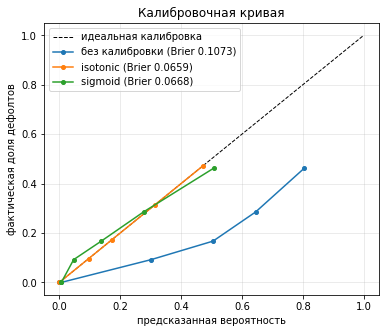

In [65]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='идеальная калибровка')

for name, p in probas.items():
    frac, mean_pred = calibration_curve(y_cal, p, n_bins=10, strategy='quantile')
    ax.plot(mean_pred, frac, 'o-', ms=4,
            label=f'{name} (Brier {brier_score_loss(y_cal, p):.4f})')

ax.set_xlabel('предсказанная вероятность')
ax.set_ylabel('фактическая доля дефолтов')
ax.set_title('Калибровочная кривая')
ax.legend(); ax.grid(alpha=.3)

 Средняя предсказанная вероятность до калибровки — 0,23 при фактической доле дефолтов 0,1007. Модель завышает риск более чем в 2 раза, для банка это критично. Резервы считаются от вероятности дефолта, и завышение вдвое означает вдвое больше замороженного капитала, о чем и говорится в условии задачи.

## Поиск порога решения

In [66]:
p_cal = cal_iso.predict_proba(X_cal)[:, 1]

def threshold_scan(y_true, proba, grid=None):
    if grid is None:
        grid = np.unique(proba)
    rows = []
    for t in grid:
        pred = (proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        rows.append({'threshold': t,
                     'approval_rate': (fn + tn) / len(y_true),
                     'default_rate': fn / (fn + tn) if (fn + tn) else np.nan,
                     'missed_defaults_rate': fn / (fn + tp)})
    return pd.DataFrame(rows)

scan = threshold_scan(y_cal, p_cal)

ok = scan[(scan.approval_rate >= 0.65) &
          (scan.default_rate <= 0.02) &
          (scan.missed_defaults_rate <= 0.04)]

print('подходящих порогов:', len(ok))
print(ok.round(4).to_string(index=False))

подходящих порогов: 1
 threshold  approval_rate  default_rate  missed_defaults_rate
    0.1059         0.6505         0.005                0.0322


 Найден 1 порог, при котором на калибровочной выборке все три требования соблюдены, threshold = 0.1059. При этом запас по default rate достаточно хороший: 0,5% при допустимых 2%. По  missed defaults запас совсем небольшой, 3,22% против предельных 4%. А approval rate упирается почти вплотную: 65.05% при минимальных 65%. 

 При таком пороге банк одобряет 65 клиентов из ста. Внутри одобренного портфеля дефолт случится у 0,57% — то есть портфель практически чистый. При этом мы жертвуем потенциально надежными клиентами, 35% клиентов получают отказ, хотя дефолт произошёл бы лишь у части из них. Именно тот компромисс, который описан в постановке задачи: банк сознательно жертвует объёмом ради качества портфеля.

## Анализ матрицы ошибок

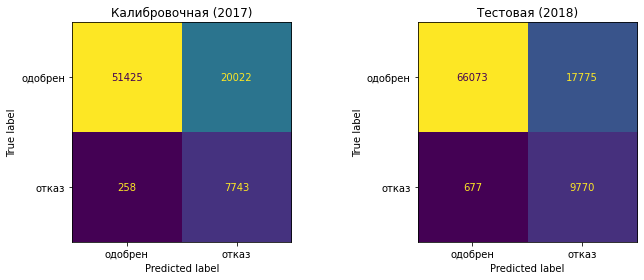

In [67]:
from sklearn.metrics import ConfusionMatrixDisplay

THRESHOLD = ok['threshold'].iloc[0]

p_cal  = cal_iso.predict_proba(X_cal)[:, 1]
p_test = cal_iso.predict_proba(test[feats])[:, 1]
y_test = test['target']

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, y_true, p) in zip(axes, [('Калибровочная (2017)', y_cal,  p_cal),
                                        ('Тестовая (2018)', y_test, p_test)]):
    pred = (p >= THRESHOLD).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_true, pred, ax=ax,
                                            display_labels=['одобрен', 'отказ'],
                                            colorbar=False, values_format='d')
    ax.set_title(name)
plt.tight_layout()

In [68]:
def full_report(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {'N': len(y_true), 'доля класса 1': y_true.mean(),
            'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
            'accuracy': accuracy_score(y_true, pred),
            'precision': precision_score(y_true, pred),
            'recall': recall_score(y_true, pred),
            'f1': f1_score(y_true, pred),
            'ROC-AUC': roc_auc_score(y_true, proba),
            'Brier': brier_score_loss(y_true, proba),
            'approval rate': (fn + tn) / len(y_true),
            'default rate': fn / (fn + tn),
            'missed defaults rate': fn / (fn + tp)}

rep = pd.DataFrame({'калибровочная (2017)': full_report(y_cal,  p_cal,  THRESHOLD),
                    'тестовая (2018)':      full_report(y_test, p_test, THRESHOLD)})
rep['diff'] = rep['тестовая (2018)'] - rep['калибровочная (2017)']
rep.round(4)

,калибровочная (2017),тестовая (2018),diff
N,79448.0000,94295.0000,14847.0000
доля класса 1,0.1007,0.1108,0.0101
TN,51425.0000,66073.0000,14648.0000
FP,20022.0000,17775.0000,-2247.0000
FN,258.0000,677.0000,419.0000
TP,7743.0000,9770.0000,2027.0000
accuracy,0.7447,0.8043,0.0596
precision,0.2789,0.3547,0.0758
recall,0.9678,0.9352,-0.0326
f1,0.4330,0.5143,0.0813


ROC-AUC на обеих выборках практически одинаков — 0,9081 и 0,9082. Это значит, что на данных следующего года она различает надёжных и проблемных заёмщиков так же хорошо, как на тех, по которым настраивалась. Само качество модели не упало.

На калибровочной выборке все три требования выполняются: одобряем 65,05% клиентов, дефолтов среди них 0,50%, пропускаем 3,22% проблемных заёмщиков. На тестовой выборке первые два требования тоже выполняются — одобрение 70,79%, дефолты среди одобренных 1,01%. Но доля пропущенных дефолтов выросла до 6,48% при допустимых 4%. В абсолютных числах мы не заметили 677 будущих неплательщиков вместо примерно 340, которых ожидали.

Вероятнее всего причина в том, что в 2018 году доля дефолтов 11,08% против 10,07% годом раньше. Калибровка настраивалась на 2017 год и на новых данных занижает вероятности. Из-за этого при том же самом пороге модель пропускает больше людей, а вместе с ними проходит и больше будущих должников. 

Отдельно стоит обратить внимание на accuracy, precision и f1 — все три на тесте выросли, потому что модель стала мягче и реже отказывала зря: ложных отказов стало 17 775 вместо 20 022. При этом пропущенных дефолтов стало вдвое больше, а эти метрики такого просто не видят. То есть модель как будто улучшилась, но по факту она стала хуже для банка, из этого видно, зачем в задаче вообще понадобились отдельные бизнес-метрики.

## Фиксирование итоговой модели

In [69]:
final = {
    'алгоритм': 'RandomForestClassifier',
    'балансировка': 'RandomUnderSampler',
    'гиперпараметры': study.best_params,
    'метрика оптимизации': 'missed defaults rate при approval rate 65%',
    'кросс-валидация': 'GroupTimeSeriesSplit, 3 фолда по календарным годам',
    'лучшее значение CV': round(study.best_value, 4),
    'калибровка': 'isotonic, обучена на калибровочной выборке 2017 года',
    'порог': round(THRESHOLD, 4),
}
pd.Series(final).to_frame('значение')

,значение
алгоритм,RandomForestClassifier
балансировка,RandomUnderSampler
гиперпараметры,"{'n_estimators': 150, 'max_depth': 12, 'min_sa..."
метрика оптимизации,missed defaults rate при approval rate 65%
кросс-валидация,"GroupTimeSeriesSplit, 3 фолда по календарным г..."
лучшее значение CV,0.234
калибровка,"isotonic, обучена на калибровочной выборке 201..."
порог,0.1059


 Пайплайн из четырёх шагов: заполнение пропусков медианой (SimpleImputer), кодирование семейное_положение через OneHotEncoder, балансировка классов RandomUnderSampler, классификатор RandomForestClassifier. Заполнение и кодирование обучаются внутри пайплайна, поэтому на каждом фолде статистики считаются заново и утечки из валидации не происходит.

 Гиперпараметры, подобранные Optuna за 10 попыток: n_estimators=150, max_depth=12, min_samples_leaf=10, max_features=0.685. Целевая функция — missed defaults rate при пороге, фиксирующем approval rate на уровне 65%. Прямая минимизация missed defaults rate была бы вырожденной: модель, объявляющая рискованными всех клиентов, даёт нулевое значение метрики при нулевом одобрении.

 Калибровка: изотоническая регрессия, обученная на отдельной калибровочной выборке 2017 года. Коэффициент Бриера улучшился с 0,1073 до 0,0659.

## Анализ важности признаков

Text(0.5, 1.0, 'Важность признаков')

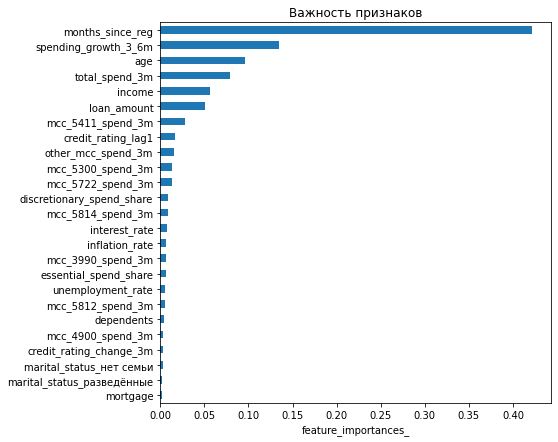

In [70]:
prep_fitted = best.named_steps['prep']
names = num_cols + list(
    prep_fitted.named_transformers_['cat'].get_feature_names_out(cat_cols))

imp = (pd.Series(best.named_steps['clf'].feature_importances_, index=names)
         .sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(7, 7))
imp.sort_values().plot.barh(ax=ax)
ax.set_xlabel('feature_importances_')
ax.set_title('Важность признаков')

In [71]:
print(imp.round(4).to_string())
print('\nсумма топ-3:', round(imp.head(3).sum(), 4))

months_since_reg              0.4219
spending_growth_3_6m          0.1351
age                           0.0962
total_spend_3m                0.0789
income                        0.0568
loan_amount                   0.0506
mcc_5411_spend_3m             0.0285
credit_rating_lag1            0.0164
other_mcc_spend_3m            0.0152
mcc_5300_spend_3m             0.0133
mcc_5722_spend_3m             0.0130
discretionary_spend_share     0.0090
mcc_5814_spend_3m             0.0084
interest_rate                 0.0077
inflation_rate                0.0067
mcc_3990_spend_3m             0.0067
essential_spend_share         0.0064
unemployment_rate             0.0053
mcc_5812_spend_3m             0.0050
dependents                    0.0046
mcc_4900_spend_3m             0.0035
credit_rating_change_3m       0.0034
marital_status_нет семьи      0.0025
marital_status_разведённые    0.0024
mortgage                      0.0023

сумма топ-3: 0.6533


 Срок отношений с банком - самый важный признак, он даёт 42,2% важности, вчетверо больше следующего. Но здесь дело больше в том, что наблюдения по клиенту заканчиваются при дефолте, то есть наличие короткой истории в данных прямо говорит о скором дефолте.

 Динамика трат работает лучше уровня трат. траты_дин_3_6 — отношение средних расходов за последние три месяца к предыдущим трём — занимает второе место, опережая абсолютную сумму всего_m3 почти вдвое. Логика вероятнее всего в том, что клиенты, у которых резко снижаются расходы, вероятнее всего приближаются к дефолту.

## Выводы по проекту

**Данные.** Восемь таблиц, 13 500 клиентов, период с 2013 по 2019 год. Пропусков и дубликатов нет. При этом 788 эпизодов просрочки короче 90 дней и дефолтом не считаются; в таблице ипотеки одни единицы, значит отсутствие клиента там означает отсутствие ипотеки; в январе 2019 нет ни одной начавшейся просрочки, похоже на пробел в выгрузке.

Данные обрываются в декабре 2019, а горизонт прогноза 12 месяцев, поэтому для последних месяцев будущие дефолты просто не видны: у декабря 2019 доля проблемных падает до 1,13% вместо обычных 10–11%. Всё после декабря 2018 из выборки убрали, иначе метрики на тесте были бы завышены.

Признаки собирали только из завершённых месяцев — даты в таблицах стоят на первое число, но описывают месяц целиком, так что траты за март на 1 марта ещё неизвестны. Всего получилось 26 признаков; из новых — изменение трат за три месяца относительно предыдущих трёх, доли обязательных и необязательных расходов, срок отношений с банком, динамика рейтинга.

Итоговая таблица: 438 379 строк, доля дефолтов 11,26%. Выборки разделили по времени — обучение на 2013–2016, калибровка на 2017, тест на 2018.

**Модель.** Из четырёх базовых вариантов без балансировки обе модели ведут себя одинаково плохо: одобряют почти всех и пропускают около 80% дефолтов. При доле проблемных в 11% модели просто выгоднее не рисковать. Из методов балансировки лучше всех сработал `RandomUnderSampler` — выиграл по всем трём бизнес-метрикам. Гиперпараметры подбирали через Optuna. 

**Калибровка.** Из-за андерсэмплинга лес учится на данных, где дефолтов 50% вместо реальных 10%, и завышает риск вдвое. Изотоническая калибровка улучшила коэффициент Бриера с 0,1073 до 0,0659 и сравняла среднюю предсказанную вероятность с фактической долей дефолтов. ROC-AUC при этом не изменился — порядок клиентов по риску калибровка не трогает.

**Порог.** Подходящее значение нашлось ровно одно, на калибровочной выборке: одобрение 65,05%, дефолты среди одобренных 0,50%, пропущенные дефолты 3,22%. Все требования выполнены, но запаса почти нет — ограничивает доля пропущенных дефолтов, 3,22% при пределе 4%.

На тесте при том же пороге одобрение выросло до 70,79%, а пропущенные дефолты — до 6,48%, то есть третье требование не выполнилось. 

**Важность признаков.** Три признака дают две трети вклада. Первый — срок отношений с банком, около 43%. Но это больше особенность данных: история клиента обрывается на дате дефолта, поэтому короткая история почти автоматически означает скорый дефолт. В реальной работе вклад этого признака будет меньше, а качество модели ниже наблюдаемого.

Второй по важности — изменение трат за три месяца, и он опережает абсолютную сумму расходов почти вдвое. Это уже более осмысленный сигнал: важнее не сколько человек тратит, а как меняется его потребление.

**Итоговый пайплайн:** заполнение пропусков и One-Hot внутри пайплайна → `RandomUnderSampler` → случайный лес (150 деревьев, глубина 12, минимум 10 объектов в листе) → изотоническая калибровка → порог 0,1059.

Рекомендации:
- Стоит попробовать добавить некоторые данные: например, о сумме поступлений, о зачислении зп, получает ли клиент зп в этом банке, не происходит ли снижения или прерывания поступления доходов, также о иной кредитной нагрузке.
- Значительную часть предсказательной силы модель берёт из срока отношений с банком, а этот признак в текущих данных завязан на том, как формировалась выборка. Перед запуском в работу качество нужно перепроверить на реальном потоке — есть риск, что оно окажется ниже, чем показывают тесты.
- Нельзя один раз подобрать порог и больше его не менять. Со временем характеристики клиентов меняются, поэтому один и тот же порог начинает работать хуже. Например, в 2018 году модель стала пропускать в два раза больше клиентов, которые потом не вернули кредит. Чтобы этого избежать, порог и калибровку модели нужно регулярно проверять и при необходимости корректировать. Обычно это делают раз в квартал или хотя бы раз в год.